# Example of the aitlas toolbox in the context of multi label image classification

The RapidAI4EO dataset contains time series of images with corresponding multilabel values. Images are either Sentinel-2 or Planet Fusion. The dataset being very heavy, this notebook considers a subset of the dataset.

## Import the required packages

In [ ]:
from aitlas.datasets import RapidAI4EODataset
from aitlas.models import ResNet50MultiLabel
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor
from aitlas.utils import image_loader

## Load the dataset

In [21]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/rapidai4eo/",
    "imagery": "PF", # PF (Planet Fusion) or S2 (Sentinel-2)
    "selection": "rgb",
    "date": "0"
}
dataset = RapidAI4EODataset(dataset_config)

print(len(dataset))

15847


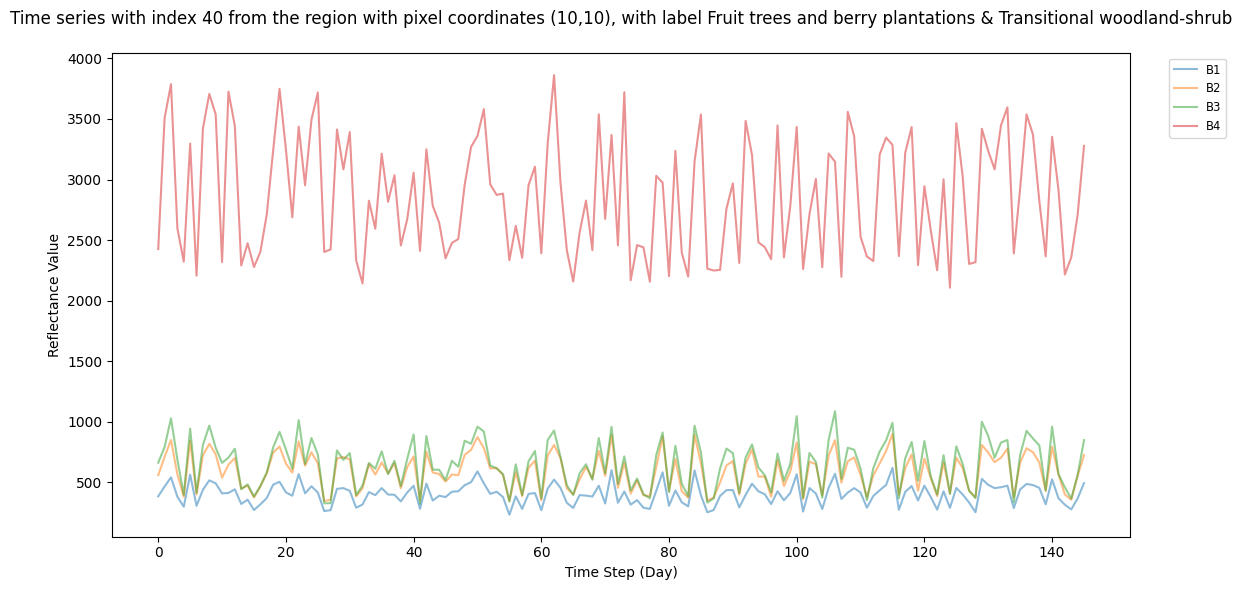

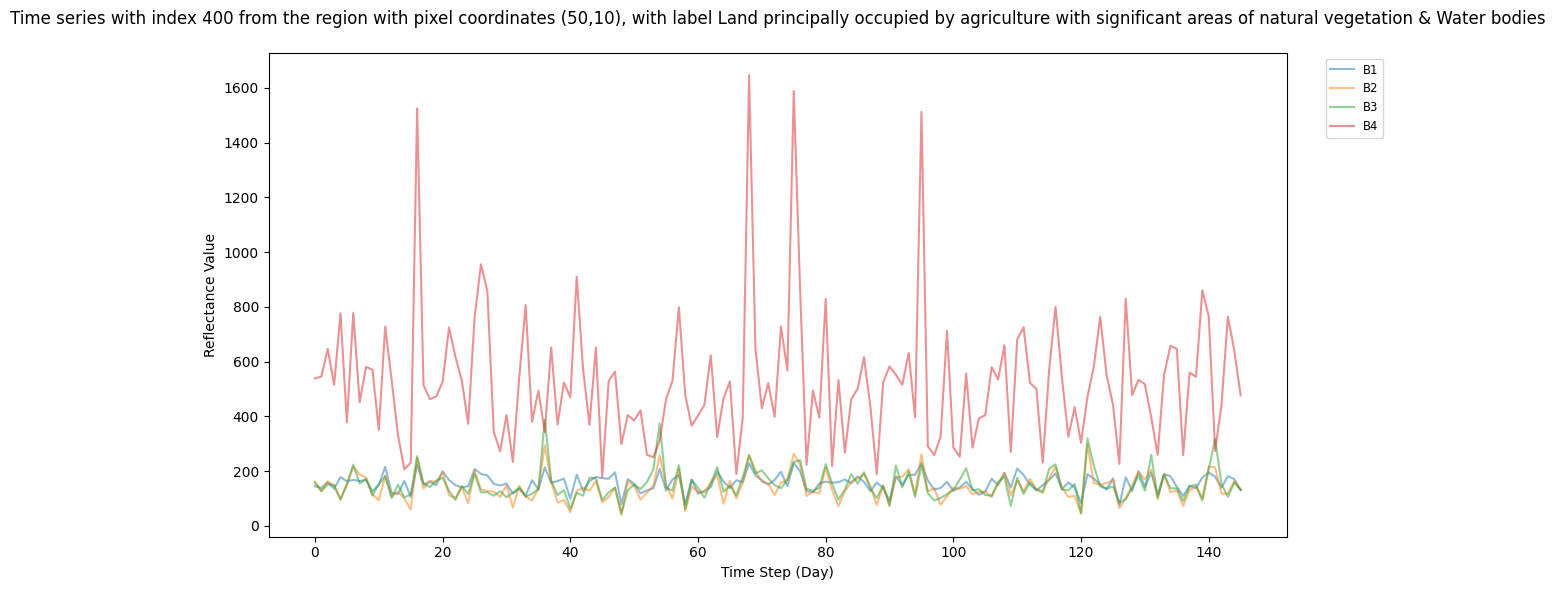

In [137]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/rapidai4eo/",
    "imagery": "PF",
    "selection": "all" # required for show_timeseries
}
dataset = RapidAI4EODataset(dataset_config)

dataset.show_timeseries(index=40, longitude=10, latitude=10) 
dataset.show_timeseries(index=400, longitude=50, latitude=10);

## Show images from the dataset

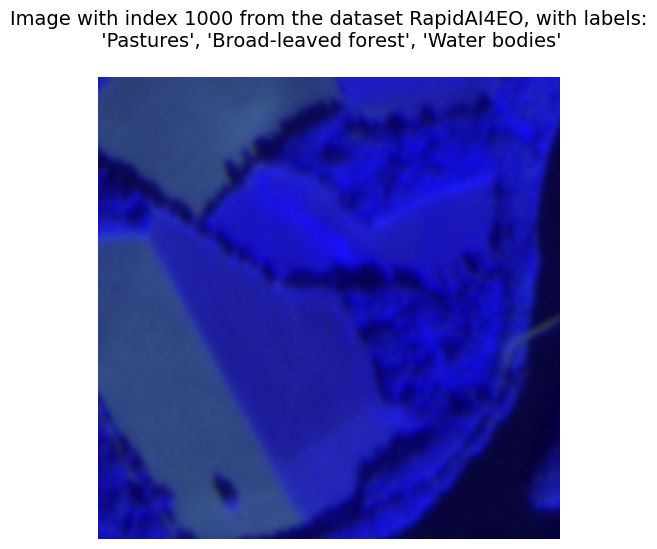

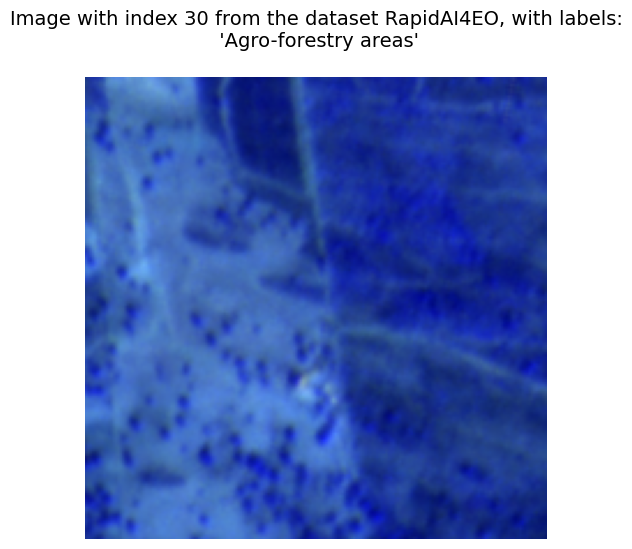

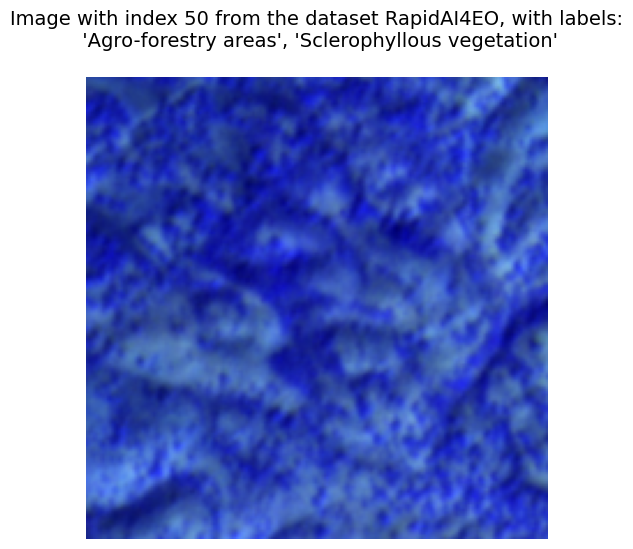

In [ ]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/rapidai4eo/",
    "imagery": "PF", # PF (Planet Fusion) or S2 (Sentinel-2)
    "selection": "rgb",
    "date": "0"
}
dataset = RapidAI4EODataset(dataset_config)

# show_image requires the "date" parameter
fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(30)
fig3 = dataset.show_image(50)

2026-02-24 18:22:33,406 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2026-02-24 18:22:33,434 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2026-02-24 18:22:33,462 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2026-02-24 18:22:33,478 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


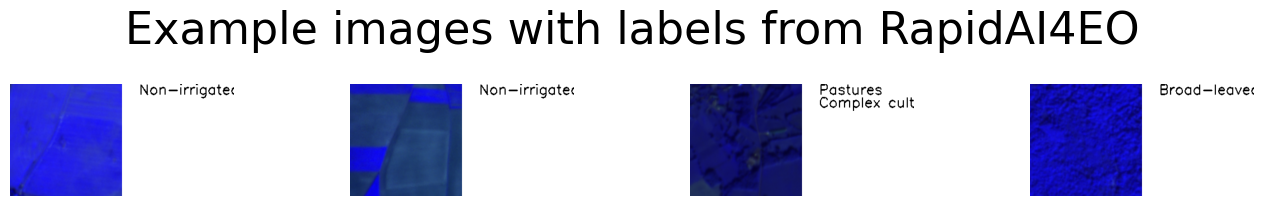

In [148]:
fig4 = dataset.show_batch(4)

## Inspect the data

In [151]:
dataset.data_distribution_table()

,Label,Count
0,Continuous urban fabric,2614
1,Discontinuous urban fabric,55252
2,Industrial or commercial units,12281
3,Road and rail networks and associated land,2867
4,Port areas,292
5,Airports,893
6,Mineral extraction sites,2967
7,Dump sites,572
8,Construction sites,1228
9,Green urban areas,1621


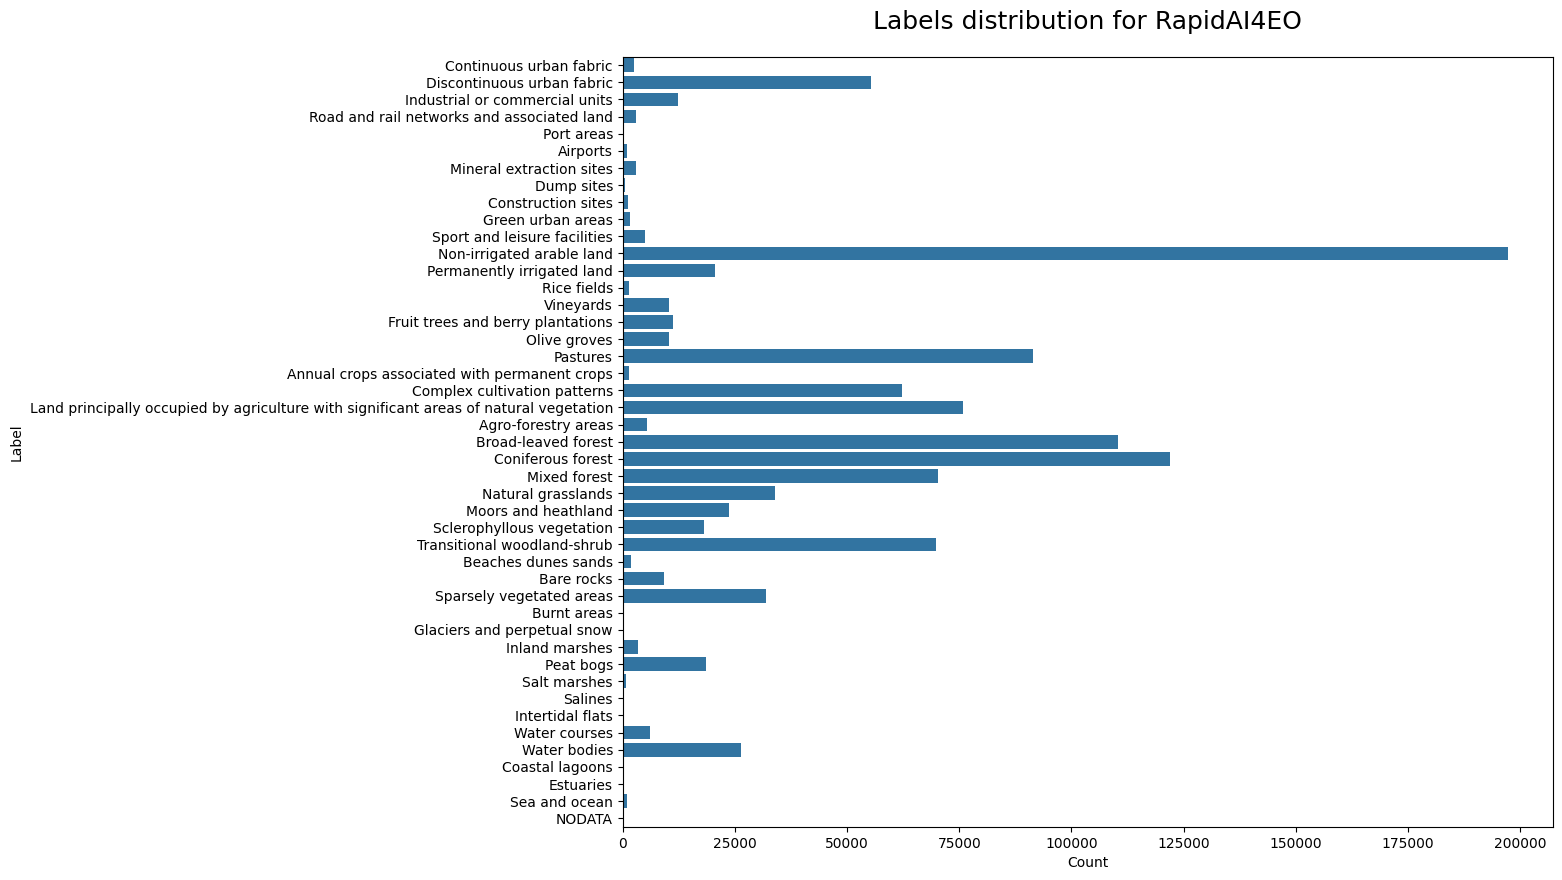

In [152]:
fig = dataset.data_distribution_barchart()

## Load train and test splits

In [5]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/rapidai4eo/",
    "imagery": "PF", 
    "selection": "rgb",
    "date": "0",
    "task": "train",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

train_dataset = RapidAI4EODataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor() 

test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/rapidai4eo/",
    "imagery": "PF", 
    "selection": "rgb",
    "date": "0",
    "task": "validation",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = RapidAI4EODataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(8452, 2817)

## Setup and create the model for training

In [6]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/rapidai4eo/"
model_config = {
    "num_classes": 45, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5, 
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = ResNet50MultiLabel(model_config)
model.prepare()

## Training and evaluation

In [7]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id='1',
)

2026-02-27 16:05:11,232 INFO Starting training.
training: 100%|██████████| 529/529 [00:23<00:00, 22.27it/s]
2026-02-27 16:05:35,021 INFO epoch: 1, time: 24, loss:  0.20891
testing on train set: 100%|██████████| 529/529 [00:15<00:00, 34.10it/s]
2026-02-27 16:05:51,218 INFO Accuracy:0.9672608718515013, Accuracy per Class:[0.99124468 0.88961193 0.97030289 0.9867487  0.99633223 0.99822527
 0.99479413 0.99952674 0.99905348 0.99148131 0.98627544 0.86689541
 0.98651207 1.         0.95728822 0.98935163 0.99858022 0.82796971
 1.         0.83424042 0.88334122 0.99183625 0.80667298 0.86405584
 0.91114529 0.97858495 0.98497397 0.958708   0.94723142 0.99869853
 0.99988168 0.99432087 0.99680549 1.         0.99645054 0.9930194
 0.99834359 1.         0.99858022 0.9875769  0.97953147 0.99621391
 1.         0.99633223 1.        ], Precision Micro:0.7839446730281012, Precision Macro:0.21042071789427866, Precision Weighted:0.6450589533310952, Precision per Class:[0.44       0.78941799 0.78947368 0.       

0.06286761516977919

## Predictions

2026-02-27 16:14:26,027 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/rapidai4eo/checkpoint.pth.tar
2026-02-27 16:14:26,750 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/rapidai4eo/checkpoint.pth.tar at epoch 11


2818


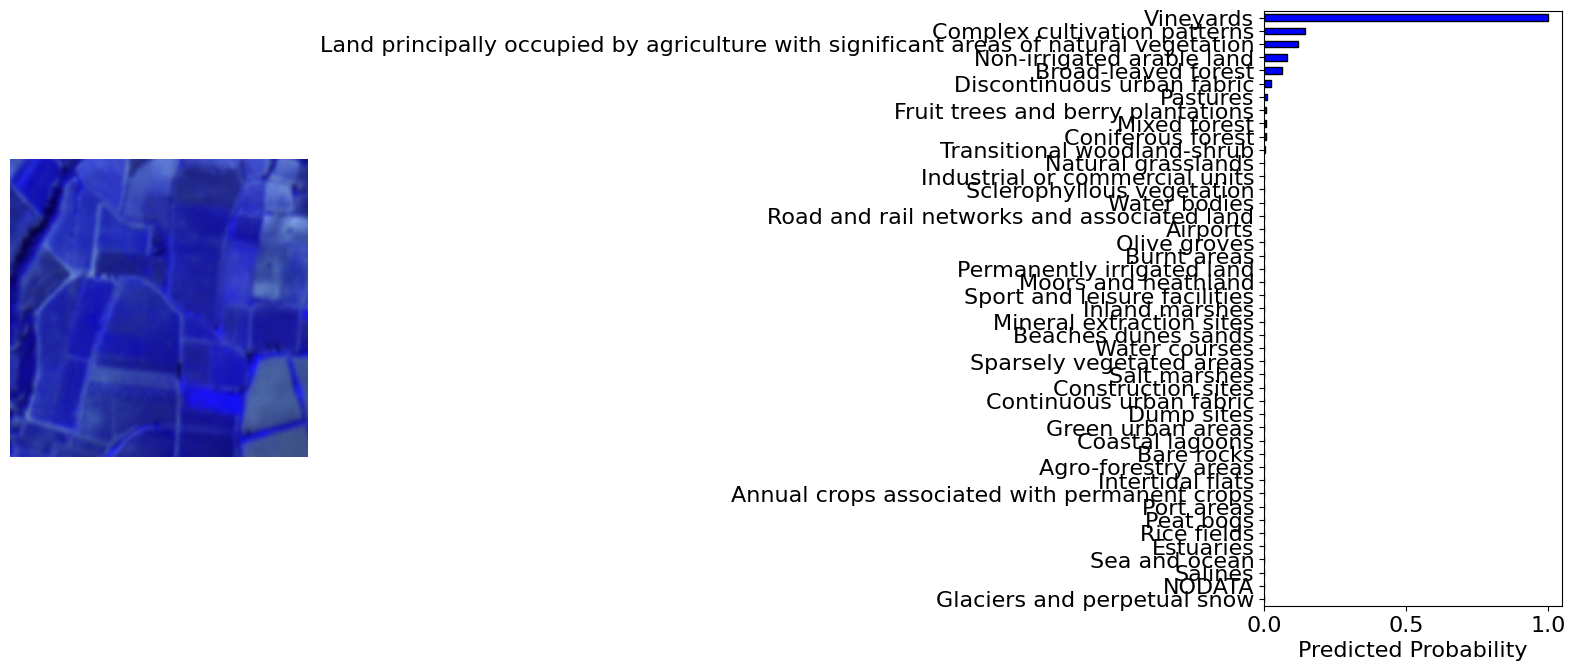

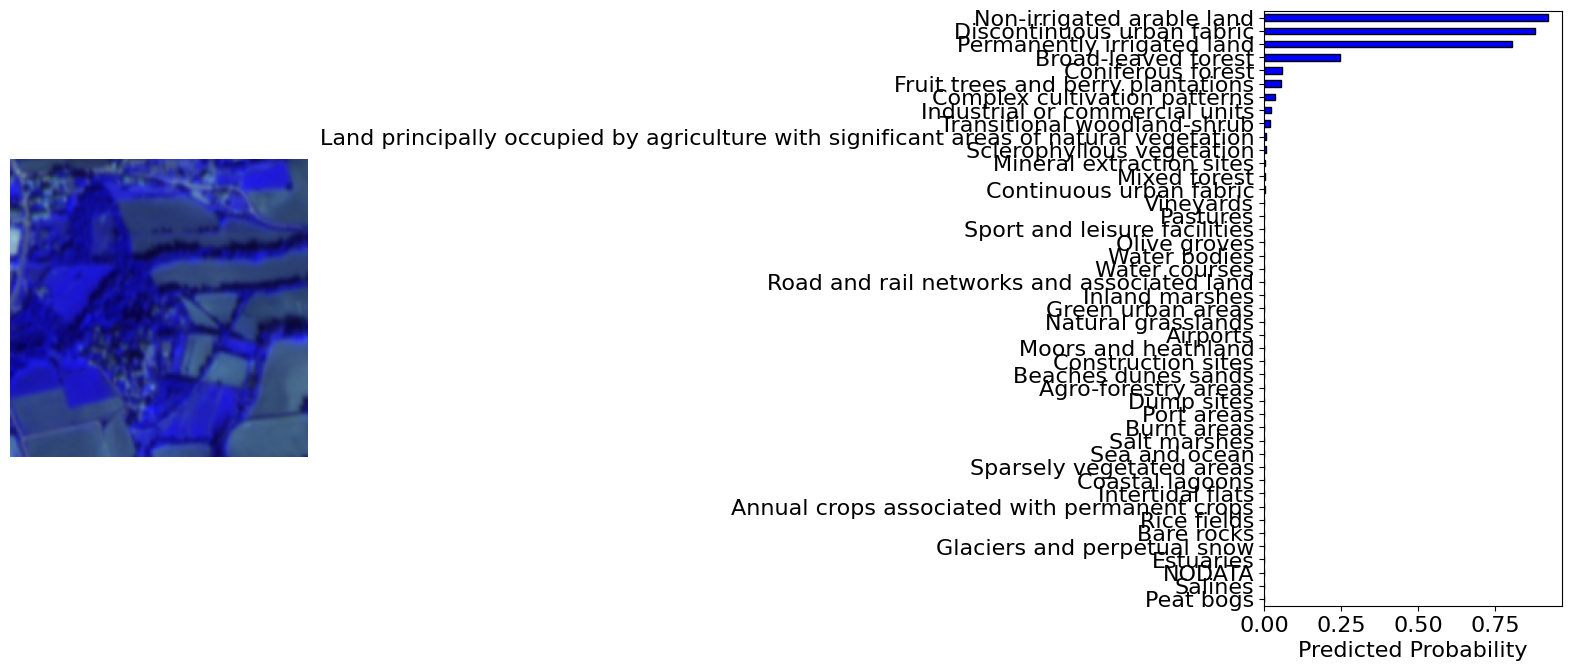

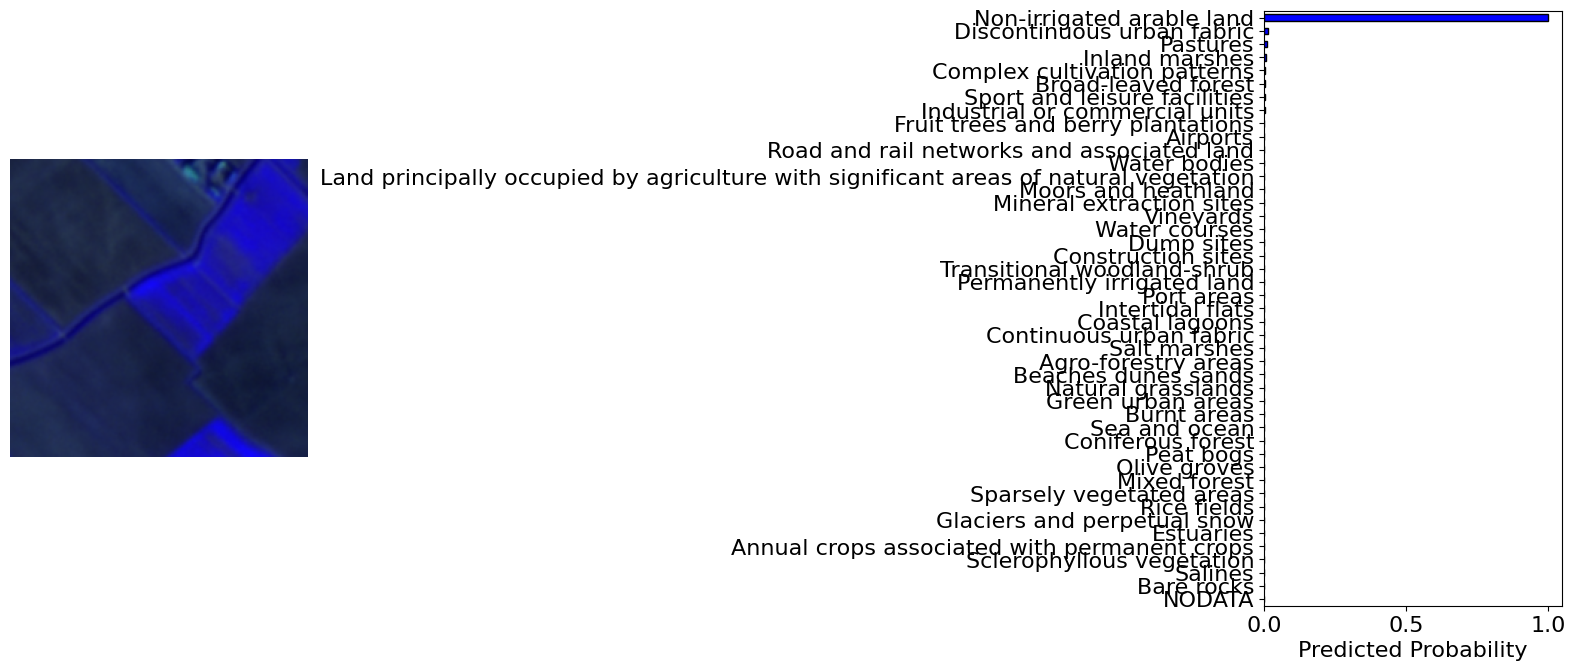

In [9]:
model_path = "/home/dragik/data/FAIR_EO/experiments/rapidai4eo/checkpoint.pth.tar"
labels = [
    "Continuous urban fabric",
    "Discontinuous urban fabric",
    "Industrial or commercial units",
    "Road and rail networks and associated land",
    "Port areas",
    "Airports",
    "Mineral extraction sites",
    "Dump sites",
    "Construction sites",
    "Green urban areas",
    "Sport and leisure facilities",
    "Non-irrigated arable land",
    "Permanently irrigated land",
    "Rice fields",
    "Vineyards",
    "Fruit trees and berry plantations",
    "Olive groves",
    "Pastures",
    "Annual crops associated with permanent crops",
    "Complex cultivation patterns",
    "Land principally occupied by agriculture with significant areas of natural vegetation",
    "Agro-forestry areas",
    "Broad-leaved forest",
    "Coniferous forest",
    "Mixed forest",
    "Natural grasslands",
    "Moors and heathland",
    "Sclerophyllous vegetation",
    "Transitional woodland-shrub",
    "Beaches dunes sands",
    "Bare rocks",
    "Sparsely vegetated areas",
    "Burnt areas",
    "Glaciers and perpetual snow",
    "Inland marshes",
    "Peat bogs",
    "Salt marshes",
    "Salines",
    "Intertidal flats",
    "Water courses",
    "Water bodies",
    "Coastal lagoons",
    "Estuaries",
    "Sea and ocean",
    "NODATA"
    ]
transform = ResizeCenterCropToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/rapidai4eo/",
    "imagery": "PF", 
    "selection": "rgb",
    "date": "0",
    "task": "test"
}

test_dataset = RapidAI4EODataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[100][0]
fig = model.predict_image(image, labels, transform)